# Hip and knee centre

### yeah i like to visualize things, it helps me understand better maybe it will for you too :) 

ma aafaile lekhya ho ni feri alteast this title part.. 

Walks through how we find the hip and knee centre on one femur.
Coordinates are voxels (2 mm): x = side to side (low x = medial), y = front to back, z = height.

In [145]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import SimpleITK as sitk
from matplotlib.patches import Circle
from scipy import ndimage

DATA = Path("preprocessed")
PATIENT = "Pat001"
PRED = None  # or a predicted mask.nii.gz

PROX, MED = 0.35, 0.6
R_VOX = (9, 14)  # 18-28 mm
N_ITER, SEED = 500, 0
VOX = 2.0

## The femur

mask shape (z, y, x): (256, 128, 96) | bone voxels: 51207
expert hip centre (x, y, z) voxels: [ 37.3  58.  217.4]


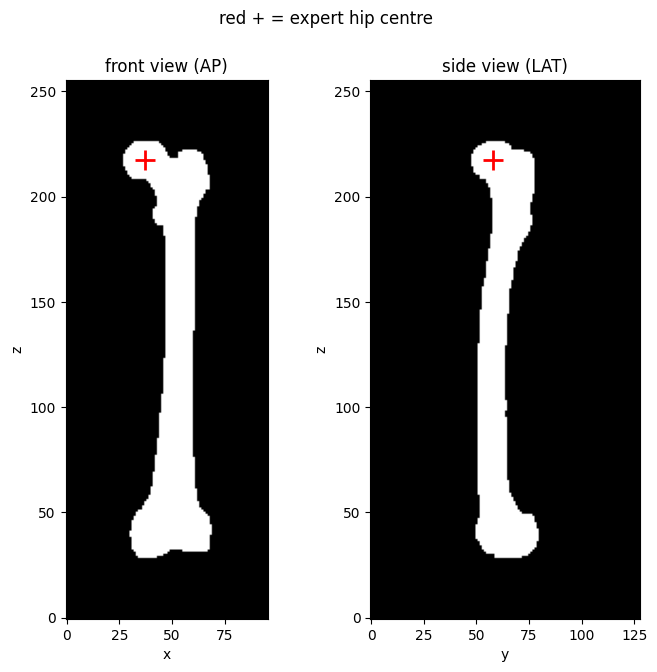

In [146]:
mask = sitk.GetArrayFromImage(sitk.ReadImage(str(PRED or DATA / PATIENT / "seg.nii.gz"))).astype(bool)
lm = json.load(open(DATA / PATIENT / "landmarks.json"))["landmarks"]
expert = np.array(lm["femurHead"]["voxel"])
print("mask shape (z, y, x):", mask.shape, "| bone voxels:", mask.sum())
print("expert hip centre (x, y, z) voxels:", expert.round(1))

fig, ax = plt.subplots(1, 2, figsize=(8, 7))
ax[0].imshow(mask.max(1), cmap="gray", origin="lower"); ax[0].set(title="front view (AP)", xlabel="x", ylabel="z")
ax[0].plot(expert[0], expert[2], "r+", ms=14, mew=2)
ax[1].imshow(mask.max(2), cmap="gray", origin="lower"); ax[1].set(title="side view (LAT)", xlabel="y", ylabel="z")
ax[1].plot(expert[1], expert[2], "r+", ms=14, mew=2)
plt.suptitle("red + = expert hip centre"); plt.show()

## The X-rays
The two DRRs the model gets as input. They line up pixel for pixel with the box, so we can draw on them directly.
Yellow = mask outline, red = expert hip, cyan = expert knee.

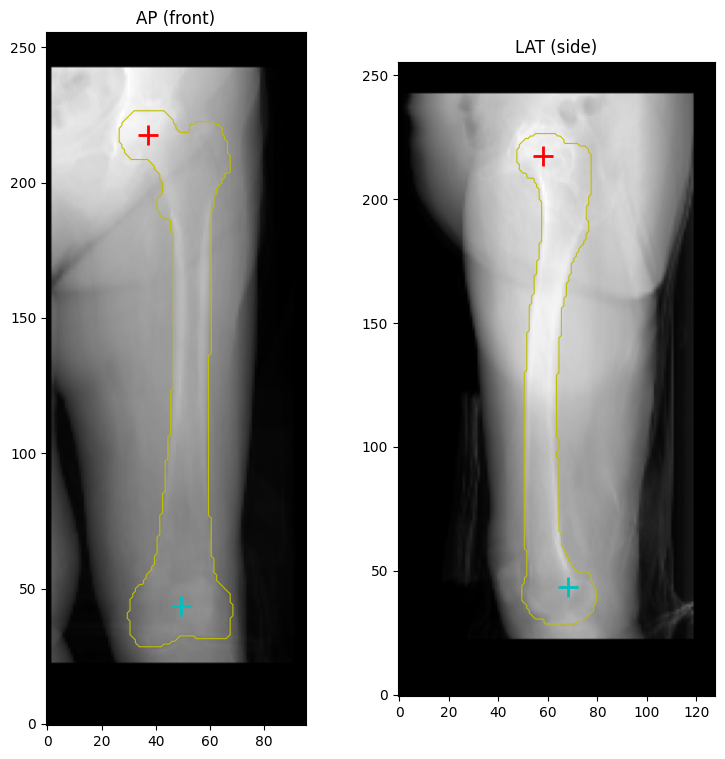

In [147]:
def load(name):
    return sitk.GetArrayFromImage(sitk.ReadImage(str(DATA / PATIENT / name))).astype(np.float32)

AP, LAT = load("ap.png")[::-1], load("lat.png")[::-1]
expert_knee = np.array(lm["kneeCenter"]["voxel"])


def show(a, im, centre, half=45, outline=None):
    # zoom in and stretch the contrast to what is visible
    h, w = im.shape
    xa, xb = int(max(centre[0] - half, 0)), int(min(centre[0] + half, w - 1))
    ya, yb = int(max(centre[1] - half, 0)), int(min(centre[1] + half, h - 1))
    crop = im[ya:yb + 1, xa:xb + 1]
    lo, hi = np.percentile(crop, [1, 99.5])
    ext = (xa - 0.5, xb + 0.5, ya - 0.5, yb + 0.5)
    a.imshow(crop, cmap="gray", origin="lower", vmin=lo, vmax=hi, extent=ext, interpolation="bilinear")
    if outline is not None:
        a.contour(outline, levels=[0.5], colors="y", linewidths=0.8)
    a.set(xlim=ext[:2], ylim=ext[2:])


fig, ax = plt.subplots(1, 2, figsize=(9, 9))
for a, im, proj, (i, j), t in [(ax[0], AP, mask.max(1), (0, 2), "AP (front)"), (ax[1], LAT, mask.max(2), (1, 2), "LAT (side)")]:
    a.imshow(im, cmap="gray", origin="lower")
    a.contour(proj, levels=[0.5], colors="y", linewidths=0.8)
    a.plot(expert[i], expert[j], "r+", ms=14, mew=2)
    a.plot(expert_knee[i], expert_knee[j], "c+", ms=14, mew=2)
    a.set_title(t)
plt.show()

## 1. Surface
Erode the mask by one voxel and subtract, so only the outer layer is left.

bone voxels: 51207 | after erosion: 40189 | surface points: 11018


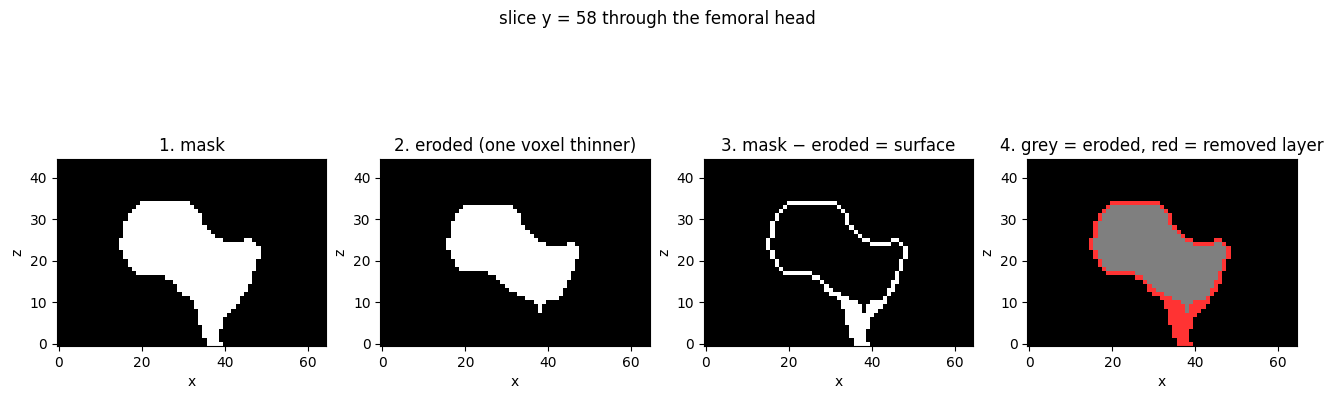

In [148]:
eroded = ndimage.binary_erosion(mask)
surface = mask & ~eroded
z, y, x = np.nonzero(surface)
p_all = np.stack([x, y, z], 1).astype(float)
print("bone voxels:", mask.sum(), "| after erosion:", eroded.sum(), "| surface points:", len(p_all))

ys = int(round(expert[1]))
zl, zh = max(int(expert[2]) - 25, 0), min(int(expert[2]) + 20, mask.shape[0])
xl_, xh_ = max(int(expert[0]) - 25, 0), int(expert[0]) + 40
fig, ax = plt.subplots(1, 4, figsize=(16, 5))
ax[0].imshow(mask[zl:zh, ys, xl_:xh_], cmap="gray", origin="lower"); ax[0].set_title("1. mask")
ax[1].imshow(eroded[zl:zh, ys, xl_:xh_], cmap="gray", origin="lower"); ax[1].set_title("2. eroded (one voxel thinner)")
ax[2].imshow(surface[zl:zh, ys, xl_:xh_], cmap="gray", origin="lower"); ax[2].set_title("3. mask − eroded = surface")
overlay = np.zeros((*mask[zl:zh, ys, xl_:xh_].shape, 3))
overlay[eroded[zl:zh, ys, xl_:xh_]] = (0.5, 0.5, 0.5)
overlay[surface[zl:zh, ys, xl_:xh_]] = (1, 0.2, 0.2)
ax[3].imshow(overlay, origin="lower"); ax[3].set_title("4. grey = eroded, red = removed layer")
for a in ax:
    a.set(xlabel="x", ylabel="z")
plt.suptitle(f"slice y = {ys} through the femoral head")
plt.show()

## 2. Top 35 %

femur z from 29 to 226 -> keep z >= 157: 4151 points


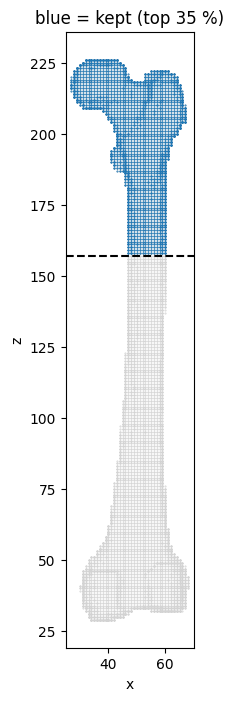

In [149]:
zmin, zmax = p_all[:, 2].min(), p_all[:, 2].max()
z_cut = zmax - PROX * (zmax - zmin)
p_top = p_all[p_all[:, 2] >= z_cut]
print(f"femur z from {zmin:.0f} to {zmax:.0f} -> keep z >= {z_cut:.0f}: {len(p_top)} points")

plt.figure(figsize=(4, 8))
plt.scatter(p_all[:, 0], p_all[:, 2], s=0.2, c="lightgray")
plt.scatter(p_top[:, 0], p_top[:, 2], s=0.2, c="tab:blue")
plt.axhline(z_cut, c="k", ls="--")
plt.gca().set(aspect="equal", xlabel="x", ylabel="z", title="blue = kept (top 35 %)"); plt.show()

## 3. Medial 60 %
This drops the greater trochanter.

x from 27 to 67 -> keep x <= 51: 2164 points


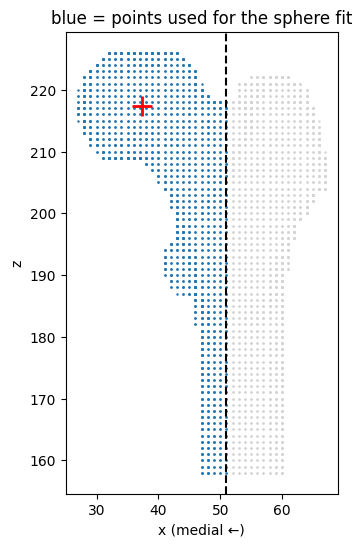

In [150]:
xl, xh = p_top[:, 0].min(), p_top[:, 0].max()
x_cut = xl + MED * (xh - xl)
p = p_top[p_top[:, 0] <= x_cut]
print(f"x from {xl:.0f} to {xh:.0f} -> keep x <= {x_cut:.0f}: {len(p)} points")

plt.figure(figsize=(6, 6))
plt.scatter(p_top[:, 0], p_top[:, 2], s=0.5, c="lightgray")
plt.scatter(p[:, 0], p[:, 2], s=0.5, c="tab:blue")
plt.axvline(x_cut, c="k", ls="--")
plt.plot(expert[0], expert[2], "r+", ms=14, mew=2)
plt.gca().set(aspect="equal", xlabel="x (medial ←)", ylabel="z", title="blue = points used for the sphere fit"); plt.show()

Same cuts on the X-ray.

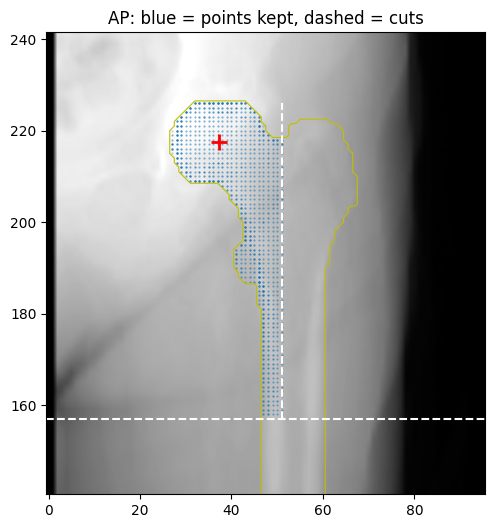

In [151]:
fig, a = plt.subplots(figsize=(6, 6))
show(a, AP, ((xl + xh) / 2, (z_cut + zmax) / 2), half=50, outline=mask.max(1))
a.scatter(p[:, 0], p[:, 2], s=0.3, c="tab:blue", alpha=0.3)
a.axhline(z_cut, c="w", ls="--")
a.plot([x_cut, x_cut], [z_cut, zmax], c="w", ls="--")
a.plot(expert[0], expert[2], "r+", ms=12, mew=2)
a.set_title("AP: blue = points kept, dashed = cuts"); plt.show()

## 4. Sphere fit

|p − c|² = r² can be written as |p|² = 2c·p + d, which is linear, so one least-squares solve gives the sphere.

In [152]:
def fit_sphere(pts):
    s, *_ = np.linalg.lstsq(np.c_[2 * pts, np.ones(len(pts))], (pts ** 2).sum(1), rcond=None)
    c = s[:3]
    r2 = s[3] + c @ c
    return (c, np.sqrt(r2)) if r2 > 0 else (None, None)


def votes(c, r, tol=2.0):
    return int((np.abs(np.linalg.norm(p - c, axis=1) - r) < tol).sum())


# should give centre 0, radius 1
print(fit_sphere(np.array([[1, 0, 0], [-1, 0, 0], [0, 1, 0], [0, 0, 1]], float)))

(array([-1.17316882e-16,  0.00000000e+00, -5.55111512e-17]), np.float64(0.9999999999999999))


## 5. RANSAC
500 tries: sphere through 4 random points, skip it if it's not head-sized, count the points on it, keep the best.

457 of 500 tries rejected for size, 43 voted
best: centre [ 37.6  58.8 217.6], radius 10.4 vox (20.7 mm), 1020 of 2164 points within 4 mm


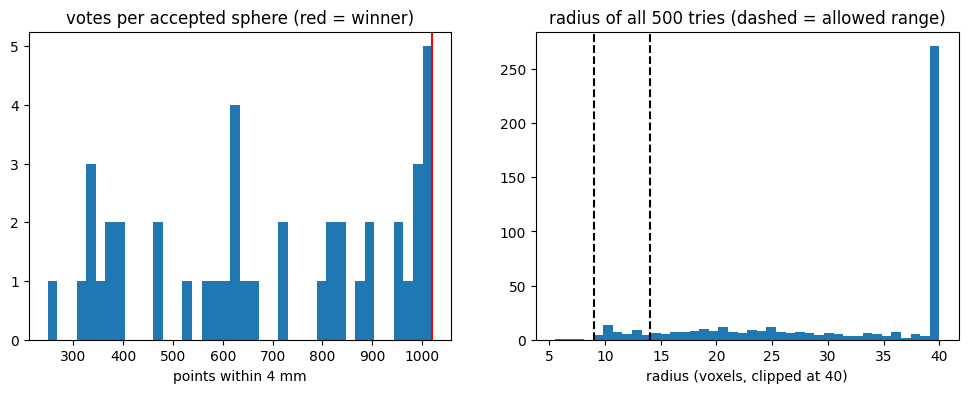

In [153]:
rng = np.random.default_rng(SEED)
tries = []
best_n, c_best, r_best = -1, None, None
for _ in range(N_ITER):
    c, r = fit_sphere(p[rng.choice(len(p), 4, replace=False)])
    if c is None or not R_VOX[0] <= r <= R_VOX[1]:
        tries.append((c, r, "wrong size", 0))
        continue
    n = votes(c, r)
    tries.append((c, r, "ok", n))
    if n > best_n:
        best_n, c_best, r_best = n, c, r

ok = [t for t in tries if t[2] == "ok"]
print(f"{len(tries) - len(ok)} of {N_ITER} tries rejected for size, {len(ok)} voted")
print(f"best: centre {c_best.round(1)}, radius {r_best:.1f} vox ({r_best * VOX:.1f} mm), {best_n} of {len(p)} points within 4 mm")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist([t[3] for t in ok], bins=40); ax[0].axvline(best_n, c="r")
ax[0].set(title="votes per accepted sphere (red = winner)", xlabel="points within 4 mm")
radii = [t[1] for t in tries if t[1] is not None]
ax[1].hist(np.clip(radii, 0, 40), bins=40); [ax[1].axvline(v, c="k", ls="--") for v in R_VOX]
ax[1].set(title="radius of all 500 tries (dashed = allowed range)", xlabel="radius (voxels, clipped at 40)")
plt.show()

Worst, middle and best try.

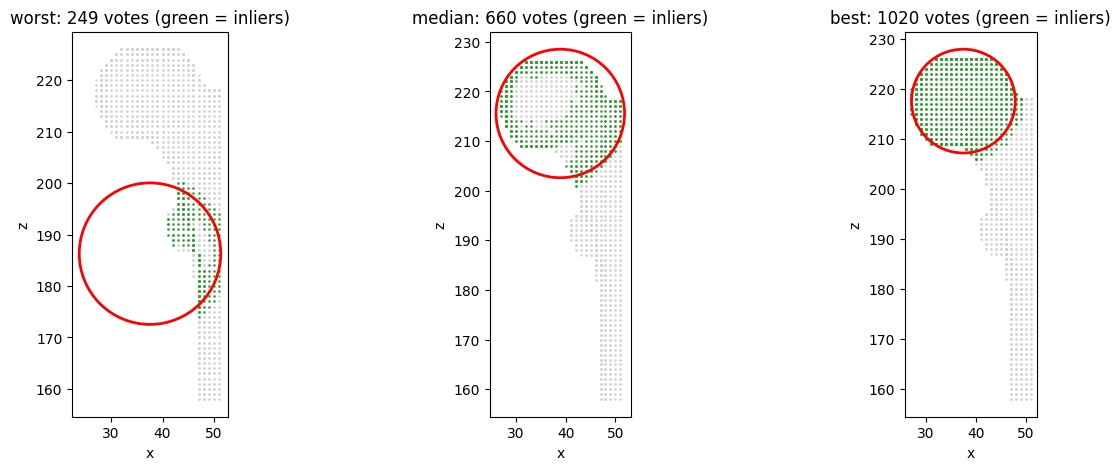

In [154]:
ranked = sorted(ok, key=lambda t: t[3])
picks = [ranked[0], ranked[len(ranked) // 2], ranked[-1]]
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, (c, r, _, n), name in zip(ax, picks, ["worst", "median", "best"]):
    a.scatter(p[:, 0], p[:, 2], s=0.5, c="lightgray")
    near = np.abs(np.linalg.norm(p - c, axis=1) - r) < 2.0
    a.scatter(p[near, 0], p[near, 2], s=0.5, c="tab:green")
    a.add_patch(Circle((c[0], c[2]), r, fill=False, ec="r", lw=2))
    a.set(aspect="equal", title=f"{name}: {n} votes (green = inliers)", xlabel="x", ylabel="z")
plt.show()

## 6. Refit
Fit again on the winner's inliers, 4 → 3 → 2 mm.

In [155]:
c, r = c_best, r_best
steps = [("RANSAC winner", c, r, best_n)]
for tol in (2.0, 1.5, 1.0):
    inl = np.abs(np.linalg.norm(p - c, axis=1) - r) < tol
    c, r = fit_sphere(p[inl])
    steps.append((f"refit, tol {tol * VOX:.0f} mm", c, r, int(inl.sum())))
hip = c

for name, c_, r_, n in steps:
    print(f"{name:20s} centre {c_.round(2)}  radius {r_ * VOX:5.1f} mm  points {n:5d}  "
          f"error vs expert {np.linalg.norm(c_ - expert) * VOX:5.2f} mm")

RANSAC winner        centre [ 37.57  58.77 217.6 ]  radius  20.7 mm  points  1020  error vs expert  1.73 mm
refit, tol 4 mm      centre [ 37.62  58.22 217.15]  radius  20.3 mm  points  1020  error vs expert  0.97 mm
refit, tol 3 mm      centre [ 37.46  58.15 217.16]  radius  20.2 mm  points   971  error vs expert  0.69 mm
refit, tol 2 mm      centre [ 37.36  58.11 217.21]  radius  20.2 mm  points   878  error vs expert  0.52 mm


## 7. Result

our hip centre (x, y, z) voxels: [ 37.36  58.11 217.21] | expert: [ 37.29  57.97 217.41]
error: 0.52 mm  (x +0.14, y +0.28, z -0.41 mm)


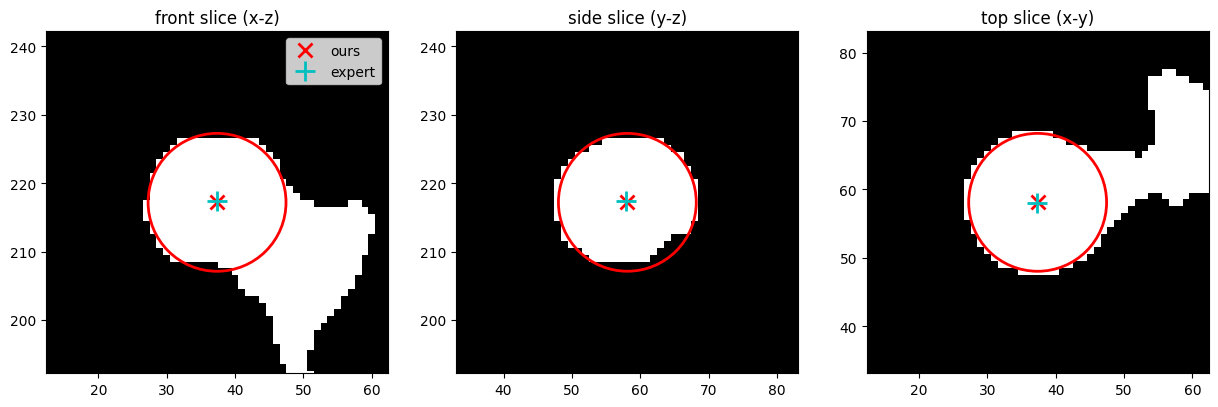

In [156]:
err = (hip - expert) * VOX
print("our hip centre (x, y, z) voxels:", hip.round(2), "| expert:", expert.round(2))
print(f"error: {np.linalg.norm(err):.2f} mm  (x {err[0]:+.2f}, y {err[1]:+.2f}, z {err[2]:+.2f} mm)")

xi, yi, zi = np.round(hip).astype(int)
views = [("front slice (x-z)", mask[:, yi, :], hip[1] - yi, (0, 2)),
         ("side slice (y-z)", mask[:, :, xi], hip[0] - xi, (1, 2)),
         ("top slice (x-y)", mask[zi], hip[2] - zi, (0, 1))]
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, (title, im, d, (i, j)) in zip(ax, views):
    a.imshow(im, cmap="gray", origin="lower")
    a.add_patch(Circle((hip[i], hip[j]), np.sqrt(max(r ** 2 - d ** 2, 0)), fill=False, ec="r", lw=2))
    a.plot(hip[i], hip[j], "rx", ms=10, mew=2, label="ours")
    a.plot(expert[i], expert[j], "c+", ms=14, mew=2, label="expert")
    a.set(xlim=(hip[i] - 25, hip[i] + 25), ylim=(hip[j] - 25, hip[j] + 25), title=title)
ax[0].legend(); plt.show()

The final sphere on the X-rays. A sphere shows up as a circle of the same radius.

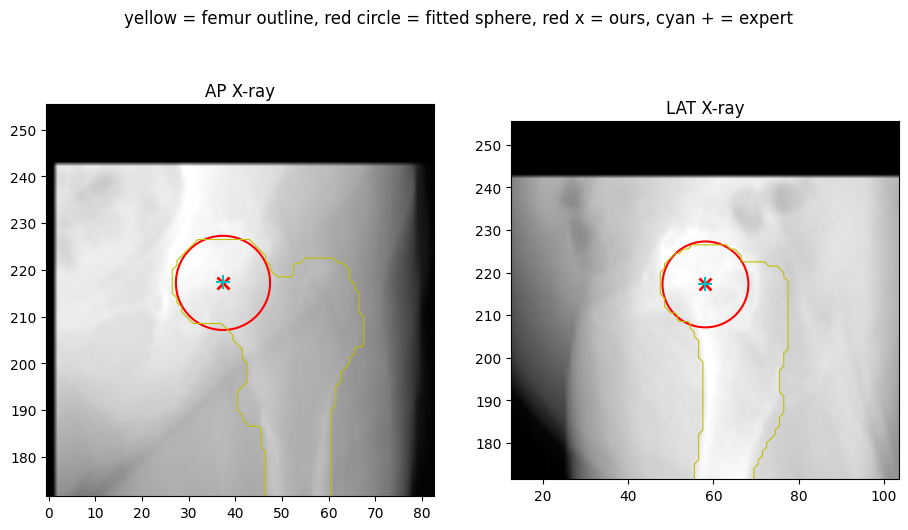

In [157]:
fig, ax = plt.subplots(1, 2, figsize=(11, 6))
for a, im, (i, j), t, outline in [(ax[0], AP, (0, 2), "AP X-ray", mask.max(1)), (ax[1], LAT, (1, 2), "LAT X-ray", mask.max(2))]:
    show(a, im, (hip[i], hip[j]), outline=outline)
    a.add_patch(Circle((hip[i], hip[j]), r, fill=False, ec="r", lw=1.5))
    a.plot(hip[i], hip[j], "rx", ms=8, mew=2)
    a.plot(expert[i], expert[j], "c+", ms=10, mew=1.5)
    a.set_title(t)
fig.suptitle("yellow = femur outline, red circle = fitted sphere, red x = ours, cyan + = expert")
plt.show()

## 8. In 3D

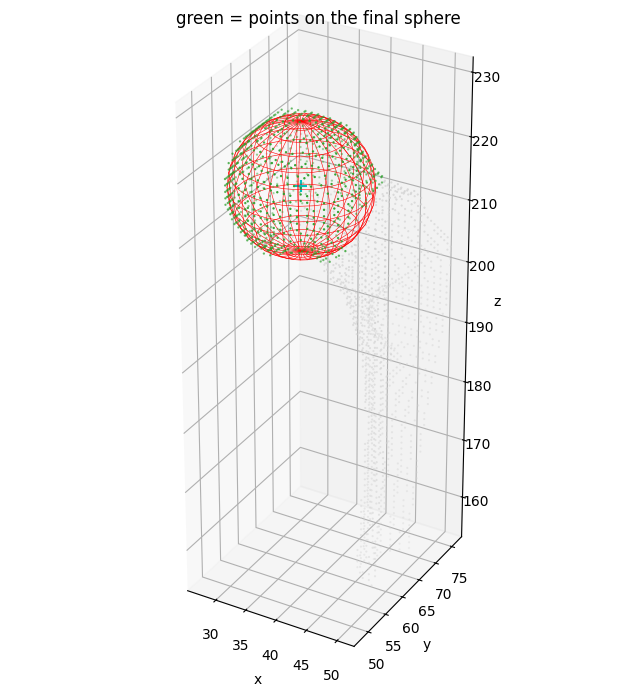

In [158]:
inl = np.abs(np.linalg.norm(p - hip, axis=1) - r) < 1.0
u, v = np.mgrid[0:2 * np.pi:30j, 0:np.pi:15j]
fig = plt.figure(figsize=(8, 8))
a = fig.add_subplot(projection="3d")
a.scatter(*p[~inl].T, s=0.3, c="lightgray")
a.scatter(*p[inl].T, s=0.5, c="tab:green")
a.plot_wireframe(hip[0] + r * np.cos(u) * np.sin(v), hip[1] + r * np.sin(u) * np.sin(v), hip[2] + r * np.cos(v),
                 color="r", lw=0.4)
a.scatter(*expert, c="c", s=80, marker="+")
a.set(xlabel="x", ylabel="y", zlabel="z", title="green = points on the final sphere")
a.set_box_aspect(np.ptp(p, 0)); plt.show()

# Knee centre

Find where the lower femur is widest (the epicondyles), take the middle there, then shift by a fixed offset learned from the experts.
Uses the solid mask, not the surface.

In [159]:
DIST, WIN = 0.30, 2
KNEE_OFFSET = np.array([-0.057, 2.901, 2.646])  # learned on all 101 femurs
expert_knee = np.array(lm["kneeCenter"]["voxel"])
print("expert knee centre (x, y, z) voxels:", expert_knee.round(1))

expert knee centre (x, y, z) voxels: [49.5 68.3 43.6]


## K1. Bottom 30 %

femur z from 29 to 226 -> keep z <= 88: 22645 bone voxels


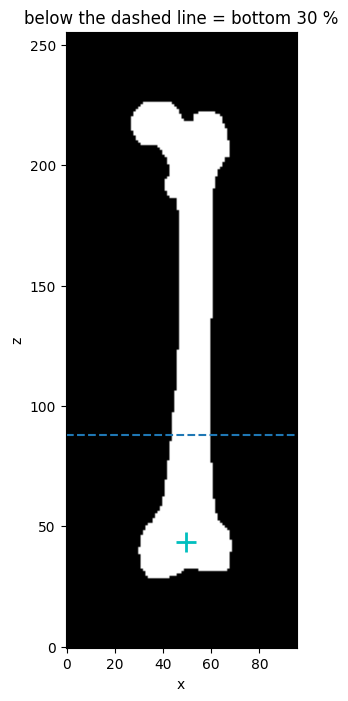

In [160]:
zz, yy, xx = np.nonzero(mask)
z_cut_k = zz.min() + DIST * (zz.max() - zz.min())
sel = zz <= z_cut_k
xk, yk, zk = xx[sel], yy[sel], zz[sel]
print(f"femur z from {zz.min()} to {zz.max()} -> keep z <= {z_cut_k:.0f}: {sel.sum()} bone voxels")

plt.figure(figsize=(4, 8))
plt.imshow(mask.max(1), cmap="gray", origin="lower")
plt.axhline(z_cut_k, c="tab:blue", ls="--")
plt.plot(expert_knee[0], expert_knee[2], "c+", ms=14, mew=2)
plt.title("below the dashed line = bottom 30 %"); plt.xlabel("x"); plt.ylabel("z"); plt.show()

## K2. Widest level

widest level z = 40, width 38 voxels (76 mm)


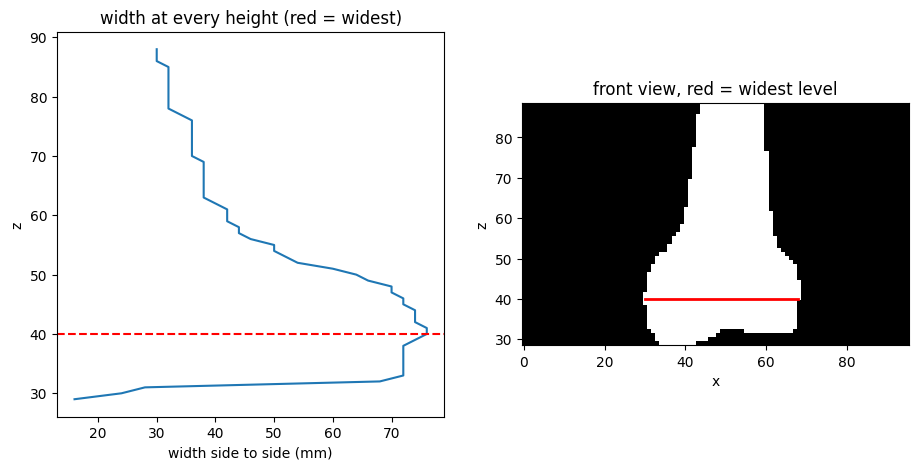

In [161]:
levels = np.unique(zk)
widths = np.array([xk[zk == q].max() - xk[zk == q].min() for q in levels])
zc = levels[np.argmax(widths)]
print(f"widest level z = {zc}, width {widths.max()} voxels ({widths.max() * VOX:.0f} mm)")

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].plot(widths * VOX, levels); ax[0].axhline(zc, c="r", ls="--")
ax[0].set(xlabel="width side to side (mm)", ylabel="z", title="width at every height (red = widest)")
lo, hi = int(levels.min()), int(z_cut_k) + 1
ax[1].imshow(mask.max(1)[lo:hi], cmap="gray", origin="lower", extent=(-0.5, mask.shape[2] - 0.5, lo - 0.5, hi - 0.5))
row = zk == zc
ax[1].plot([xk[row].min(), xk[row].max()], [zc, zc], "r-", lw=2)
ax[1].set(title="front view, red = widest level", xlabel="x", ylabel="z")
plt.show()

## K3. Middle at that level
x = halfway between the medial and lateral edge, y = average, using ±2 slices.

medial point (x, y): 30 76 | lateral point (x, y): 68 68
knee centre before offset (x, y, z): [49.   64.98 40.  ]


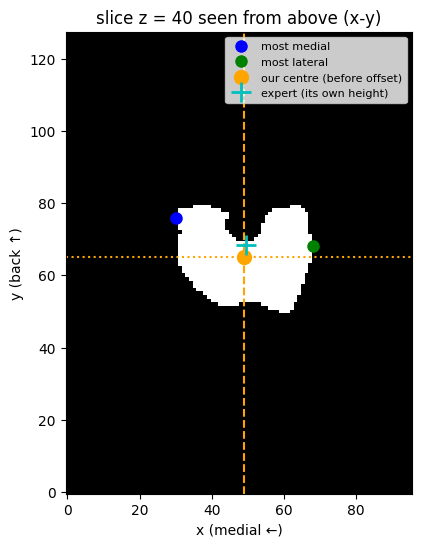

In [162]:
m = np.abs(zk - zc) <= WIN
i_med, i_lat = np.argmin(xk[m]), np.argmax(xk[m])
knee_raw = np.array([(xk[m].min() + xk[m].max()) / 2.0, yk[m].mean(), zc], float)
print("medial point (x, y):", xk[m][i_med], yk[m][i_med], "| lateral point (x, y):", xk[m][i_lat], yk[m][i_lat])
print("knee centre before offset (x, y, z):", knee_raw.round(2))

plt.figure(figsize=(7, 6))
plt.imshow(mask[zc], cmap="gray", origin="lower")
plt.plot(xk[m][i_med], yk[m][i_med], "bo", ms=8, label="most medial")
plt.plot(xk[m][i_lat], yk[m][i_lat], "go", ms=8, label="most lateral")
plt.axvline(knee_raw[0], c="orange", ls="--"); plt.axhline(knee_raw[1], c="orange", ls=":")
plt.plot(knee_raw[0], knee_raw[1], "o", c="orange", ms=10, label="our centre (before offset)")
plt.plot(expert_knee[0], expert_knee[1], "c+", ms=14, mew=2, label="expert (its own height)")
plt.title(f"slice z = {zc} seen from above (x-y)"); plt.xlabel("x (medial ←)"); plt.ylabel("y (back ↑)")
plt.legend(fontsize=8); plt.show()

## K4. Offset
Our point ends up ~6 mm too far forward and ~5 mm too low, about the same for every femur, so we shift it.

before offset  error  9.82 mm  (x -0.93, y -6.67, z -7.14 mm)
after offset   error  2.30 mm  (x -1.04, y -0.87, z -1.85 mm)
offset in mm: [-0.1  5.8  5.3]


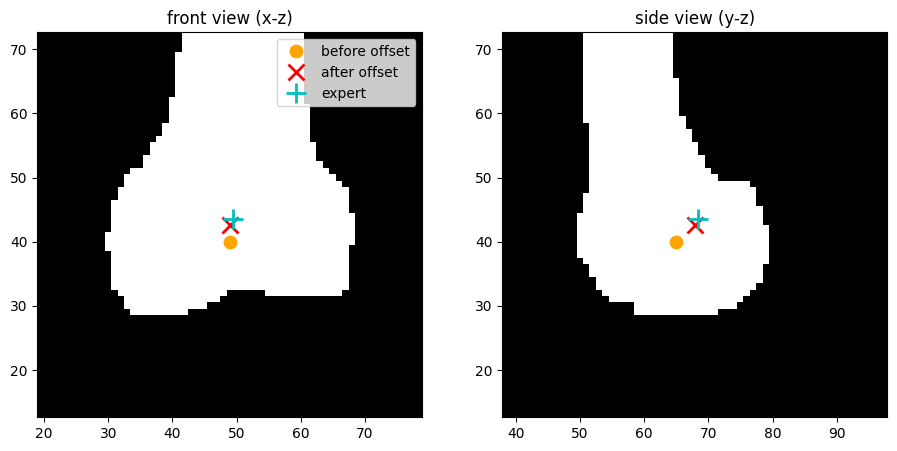

In [163]:
knee = knee_raw + KNEE_OFFSET
for name, k in [("before offset", knee_raw), ("after offset", knee)]:
    e = (k - expert_knee) * VOX
    print(f"{name:14s} error {np.linalg.norm(e):5.2f} mm  (x {e[0]:+.2f}, y {e[1]:+.2f}, z {e[2]:+.2f} mm)")
print("offset in mm:", (KNEE_OFFSET * VOX).round(1))

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
for a, im, (i, j), title in [(ax[0], mask.max(1), (0, 2), "front view (x-z)"), (ax[1], mask.max(2), (1, 2), "side view (y-z)")]:
    a.imshow(im, cmap="gray", origin="lower")
    a.plot(knee_raw[i], knee_raw[j], "o", c="orange", ms=9, label="before offset")
    a.plot(knee[i], knee[j], "rx", ms=11, mew=2, label="after offset")
    a.plot(expert_knee[i], expert_knee[j], "c+", ms=14, mew=2, label="expert")
    a.set(xlim=(knee[i] - 30, knee[i] + 30), ylim=(knee[j] - 30, knee[j] + 30), title=title)
ax[0].legend(); plt.show()

The knee steps on the X-rays.

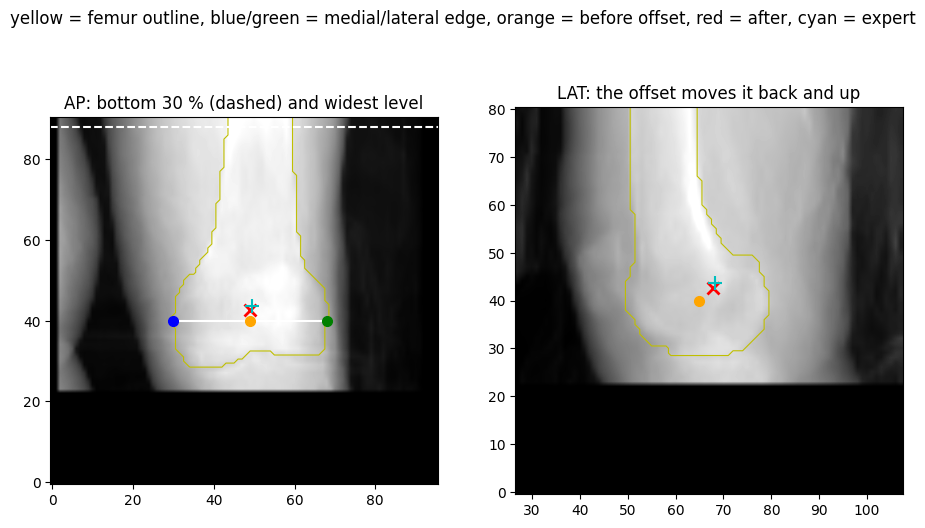

In [164]:
fig, ax = plt.subplots(1, 2, figsize=(11, 6))
show(ax[0], AP, (knee[0], zc), half=50, outline=mask.max(1))
ax[0].axhline(z_cut_k, c="w", ls="--")
ax[0].plot([xk[m].min(), xk[m].max()], [zc, zc], "w-", lw=1.5)
ax[0].plot(xk[m][i_med], zc, "bo", ms=7)
ax[0].plot(xk[m][i_lat], zc, "go", ms=7)
ax[0].set_title("AP: bottom 30 % (dashed) and widest level")

show(ax[1], LAT, (knee[1], zc), half=40, outline=mask.max(2))
ax[1].set_title("LAT: the offset moves it back and up")


for a, (i, j) in zip(ax, [(0, 2), (1, 2)]):
    a.plot(knee_raw[i], knee_raw[j], "o", c="orange", ms=7)
    a.plot(knee[i], knee[j], "rx", ms=8, mew=2)
    a.plot(expert_knee[i], expert_knee[j], "c+", ms=10, mew=1.5)
fig.suptitle("yellow = femur outline, blue/green = medial/lateral edge, orange = before offset, red = after, cyan = expert")
plt.show()

# Mechanical axis

axis length: ours 350.4 mm, expert 349.1 mm
hip error 0.52 mm | knee error 2.30 mm | axis angle error 0.29 deg


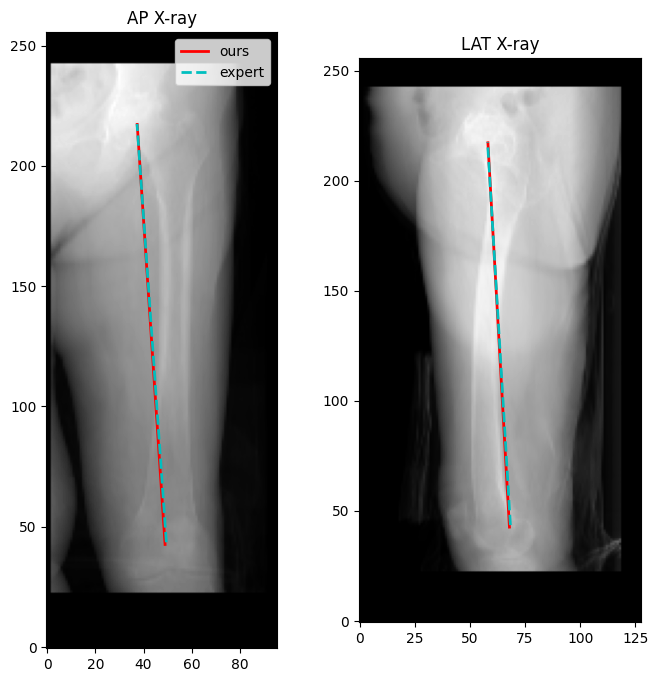

In [165]:
def angle(v1, v2):
    return float(np.degrees(np.arccos(np.clip(v1 @ v2 / np.linalg.norm(v1) / np.linalg.norm(v2), -1, 1))))

ours, exp_axis = hip - knee, expert - expert_knee
print(f"axis length: ours {np.linalg.norm(ours) * VOX:.1f} mm, expert {np.linalg.norm(exp_axis) * VOX:.1f} mm")
print(f"hip error {np.linalg.norm(hip - expert) * VOX:.2f} mm | knee error {np.linalg.norm(knee - expert_knee) * VOX:.2f} mm | "
      f"axis angle error {angle(ours, exp_axis):.2f} deg")

fig, ax = plt.subplots(1, 2, figsize=(8, 8))
for a, im, (i, j), title in [(ax[0], AP, (0, 2), "AP X-ray"), (ax[1], LAT, (1, 2), "LAT X-ray")]:
    a.imshow(im, cmap="gray", origin="lower")
    a.plot([knee[i], hip[i]], [knee[j], hip[j]], "r-", lw=2, label="ours")
    a.plot([expert_knee[i], expert[i]], [expert_knee[j], expert[j]], "c--", lw=2, label="expert")
    a.set_title(title)
ax[0].legend(); plt.show()

## All patients
Same thing on all 101 ground-truth masks. Each knee offset comes from the other 100 patients.

hip error (mm)               median  0.39   IQR  0.25- 0.55   max  1.59
knee error (mm)              median  3.16   IQR  2.11- 4.55   max 15.63
knee error, no offset (mm)   median  8.00   IQR  6.25-10.09   max 21.06
axis angle error (deg)       median  0.29   IQR  0.14- 0.39   max  2.28


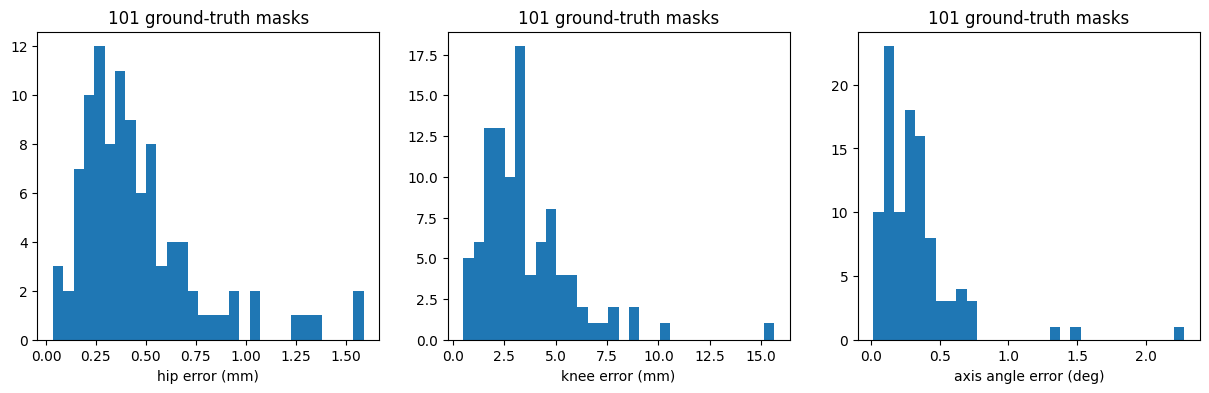

In [166]:
def fit_head(m):
    zz, yy, xx = np.nonzero(m & ~ndimage.binary_erosion(m))
    q = np.stack([xx, yy, zz], 1).astype(float)
    q = q[q[:, 2] >= q[:, 2].max() - PROX * np.ptp(q[:, 2])]
    q = q[q[:, 0] <= q[:, 0].min() + MED * np.ptp(q[:, 0])]
    g = np.random.default_rng(SEED)
    bn, cb, rb = -1, None, None
    for _ in range(N_ITER):
        c_, r_ = fit_sphere(q[g.choice(len(q), 4, replace=False)])
        if c_ is None or not R_VOX[0] <= r_ <= R_VOX[1]:
            continue
        n = (np.abs(np.linalg.norm(q - c_, axis=1) - r_) < 2.0).sum()
        if n > bn:
            bn, cb, rb = n, c_, r_
    for tol in (2.0, 1.5, 1.0):
        cb, rb = fit_sphere(q[np.abs(np.linalg.norm(q - cb, axis=1) - rb) < tol])
    return cb


def fit_knee(m):
    zz, yy, xx = np.nonzero(m)
    s = zz <= zz.min() + DIST * (zz.max() - zz.min())
    xs, ys, zs = xx[s], yy[s], zz[s]
    lv = np.unique(zs)
    z0 = lv[int(np.argmax([xs[zs == q].max() - xs[zs == q].min() for q in lv]))]
    w = np.abs(zs - z0) <= WIN
    return np.array([(xs[w].min() + xs[w].max()) / 2.0, ys[w].mean(), z0], float)


res = {}
for d in sorted(x for x in DATA.iterdir() if (x / "seg.nii.gz").exists()):
    m = sitk.GetArrayFromImage(sitk.ReadImage(str(d / "seg.nii.gz"))).astype(bool)
    L = json.load(open(d / "landmarks.json"))["landmarks"]
    res[d.name] = dict(hip=fit_head(m), knee_raw=fit_knee(m),
                       e_hip=np.array(L["femurHead"]["voxel"]), e_knee=np.array(L["kneeCenter"]["voxel"]))

diffs = np.array([r["e_knee"] - r["knee_raw"] for r in res.values()])
n = len(diffs)
rows = []
for k, (pid, r) in enumerate(res.items()):
    off = (diffs.sum(0) - diffs[k]) / (n - 1)
    kn = r["knee_raw"] + off
    rows.append([np.linalg.norm(r["hip"] - r["e_hip"]) * VOX, np.linalg.norm(kn - r["e_knee"]) * VOX,
                 np.linalg.norm(r["knee_raw"] - r["e_knee"]) * VOX, angle(r["hip"] - kn, r["e_hip"] - r["e_knee"])])
rows = np.array(rows)

for i, name in enumerate(["hip error (mm)", "knee error (mm)", "knee error, no offset (mm)", "axis angle error (deg)"]):
    v = rows[:, i]
    print(f"{name:28s} median {np.median(v):5.2f}   IQR {np.percentile(v, 25):5.2f}-{np.percentile(v, 75):5.2f}   max {v.max():5.2f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, i, t in zip(ax, [0, 1, 3], ["hip error (mm)", "knee error (mm)", "axis angle error (deg)"]):
    a.hist(rows[:, i], bins=30); a.set(title=f"{n} ground-truth masks", xlabel=t)
plt.show()